Enter the value of N: 5
Enter the row for the first queen (1 to 5): 1
Enter the column for the first queen (1 to 5): 1

Solutions with first queen fixed at (1, 1):

Solution 1:
1 0 0 0 0
0 0 1 0 0
0 0 0 0 1
0 1 0 0 0
0 0 0 1 0

Solution 2:
1 0 0 0 0
0 0 0 1 0
0 1 0 0 0
0 0 0 0 1
0 0 1 0 0

Total solutions: 2

N	Execution Time (seconds)	Peak Memory (KB)
4	0.00000887			1.727
5	0.00002483			1.953
6	0.00009093			2.164
7	0.00030927			2.391
8	0.00106103			2.680
9	0.00449087			3.031
10	0.02000923			4.462
11	0.09836313			3.430


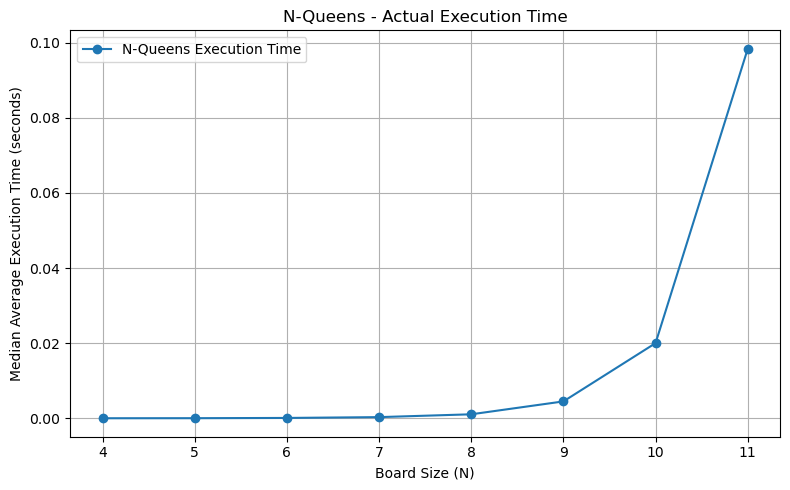

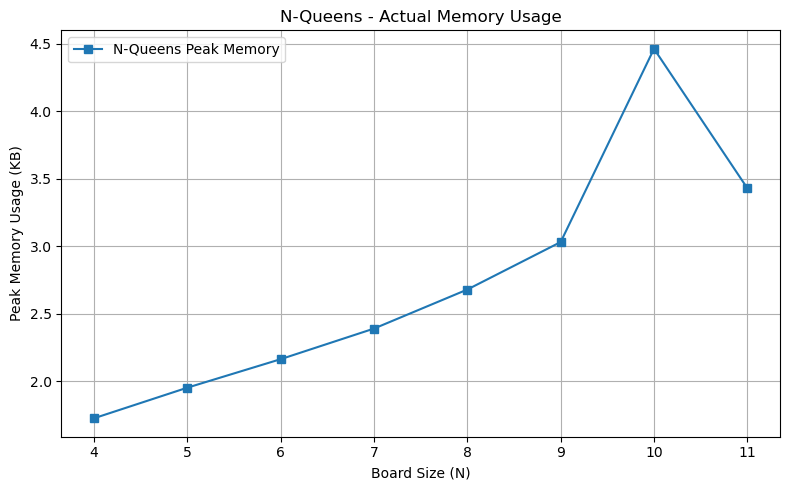

In [ ]:

import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics


# N-Queens with an optional fixed queen
def n_queens_count(n, fixed_position=None, print_solutions=False):
    board = [['0'] * n for _ in range(n)]
    columns = [False] * n
    pos_diag = [False] * (2 * n - 1)
    neg_diag = [False] * (2 * n - 1)
    solutions = 0

    # Place the user's first queen
    if fixed_position is not None:
        r, c = fixed_position
        board[r][c] = '1'
        columns[c] = True
        pos_diag[r + c] = True
        neg_diag[r - c + n - 1] = True

    def show_board():
        for row in board:
            print(' '.join(row))
        print()

    def backtrack(row):
        nonlocal solutions

        if row == n:
            solutions += 1

            if print_solutions:
                print(f"Solution {solutions}:")
                show_board()
            return

        # Keep the fixed queen in its selected row
        if fixed_position is not None and row == fixed_position[0]:
            backtrack(row + 1)
            return

        for col in range(n):
            if (columns[col] or pos_diag[row + col]
                    or neg_diag[row - col + n - 1]):
                continue

            board[row][col] = '1'
            columns[col] = True
            pos_diag[row + col] = True
            neg_diag[row - col + n - 1] = True

            backtrack(row + 1)

            board[row][col] = '0'
            columns[col] = False
            pos_diag[row + col] = False
            neg_diag[row - col + n - 1] = False

    backtrack(0)
    return solutions


# Measure execution time
def measure_time(function, *args, repeats=3, runs_per_repeat=3):
    times = []

    for _ in range(repeats):
        start = perf_counter()

        for _ in range(runs_per_repeat):
            function(*args)

        times.append((perf_counter() - start) / runs_per_repeat)

    return statistics.median(times)


# Measure peak memory in KB
def measure_memory(function, *args, repeats=3):
    peaks = []

    for _ in range(repeats):
        tracemalloc.start()

        try:
            function(*args)
            current, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()

        peaks.append(peak / 1024)

    return statistics.median(peaks)


# User input
n = int(input("Enter the value of N: "))

if n <= 0:
    print("N must be a positive integer.")
    raise SystemExit

row = int(input(f"Enter the row for the first queen (1 to {n}): "))
column = int(input(f"Enter the column for the first queen (1 to {n}): "))

if not (1 <= row <= n and 1 <= column <= n):
    print("Invalid queen position!")
    raise SystemExit

fixed_position = (row - 1, column - 1)

print(f"\nSolutions with first queen fixed at ({row}, {column}):\n")

solutions = n_queens_count(
    n, fixed_position, print_solutions=True
)

if solutions == 0:
    print("No solutions found for this position.")

print("Total solutions:", solutions)


# Benchmark standard N-Queens for different board sizes
sizes = list(range(4, 12))
execution_times = []
peak_memory = []

for size in sizes:
    execution_times.append(
        measure_time(n_queens_count, size)
    )

    peak_memory.append(
        measure_memory(n_queens_count, size)
    )


# Display measured results
print("\nN\tExecution Time (seconds)\tPeak Memory (KB)")

for size, t, m in zip(sizes, execution_times, peak_memory):
    print(f"{size}\t{t:.8f}\t\t\t{m:.3f}")


# Graph 1: Actual execution time
plt.figure(figsize=(8, 5))
plt.plot(sizes, execution_times, marker='o',
         label="N-Queens Execution Time")

plt.xlabel("Board Size (N)")
plt.ylabel("Median Average Execution Time (seconds)")
plt.title("N-Queens - Actual Execution Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Graph 2: Actual memory usage
plt.figure(figsize=(8, 5))
plt.plot(sizes, peak_memory, marker='s',
         label="N-Queens Peak Memory")

plt.xlabel("Board Size (N)")
plt.ylabel("Peak Memory Usage (KB)")
plt.title("N-Queens - Actual Memory Usage")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
